In [1]:
# Install dependencies (run once)
!pip install transformers datasets torch scikit-learn pandas matplotlib seaborn accelerate sentencepiece -q

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import json
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import set_seed
import os

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

In [4]:
# =========================
# CONFIG
# =========================
DATA_PATH = "/content/drive/MyDrive/conversation_en.json"
#AUGMENTED_TRAIN_PATH = "/content/drive/MyDrive/final_train_augmented_v2.csv"
AUGMENTED_TRAIN_PATH = "/content/drive/MyDrive/final_train_augmented_v2_4class.csv"
TRANSLATED_CN_PATH = "/content/drive/MyDrive/conversation_cn_translated_en_deepseek_v4flash.json"

RESULTS_DIR = "/content/drive/MyDrive/intent9Aug/context_ablation_current_only_4class"
os.makedirs(RESULTS_DIR, exist_ok=True)

MAX_LEN = 256
RANDOM_STATE = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_TRAIN = 0.20
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
NUM_EPOCHS = 5

VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise"]
label2id = {"Chitchat": 0, "Interpret": 1, "Reveal": 2, "Revise": 3}
id2label = {v: k for k, v in label2id.items()}

print("Labels:", label2id)
print("LR:", LEARNING_RATE, "weight_decay:", WEIGHT_DECAY)

CONTEXT_CONDITION = "current_utterance_only"
print("Context condition:", CONTEXT_CONDITION)


Labels: {'Chitchat': 0, 'Interpret': 1, 'Reveal': 2, 'Revise': 3}
LR: 2e-05 weight_decay: 0.01
Context condition: current_utterance_only


In [5]:
# =========================
# LOAD ORIGINAL ENGLISH DATA
# =========================
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

df_turns_full = pd.DataFrame(all_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)

df_turns_full["conversation_id"] = df_turns_full["conversation_id"].astype(str)
df_turns_full["turn_index"] = df_turns_full["turn_index"].astype(int)
df_turns_full["role"] = df_turns_full["role"].astype(str).str.lower()
df_turns_full["text"] = df_turns_full["text"].fillna("").astype(str)

target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Original full turn rows:", len(df_turns_full))
print("Original 4-class target rows:", len(target_df))
print("Original conversations:", target_df["conversation_id"].nunique())
print(target_df[["conversation_id", "turn_index", "role", "intent"]].head())

Original full turn rows: 5633
Original 4-class target rows: 3179
Original conversations: 825
  conversation_id  turn_index  role     intent
0          100204           0  user     Reveal
1          100204           2  user     Reveal
2          100325           0  user   Chitchat
3          100325           2  user     Reveal
4          100325           4  user  Interpret


In [6]:
# =========================
#  GROUPED SINGLE SPLIT
# =========================
gss1 = GroupShuffleSplit(
    n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
train_val_idx, test_idx = next(
    gss1.split(target_df, groups=target_df["conversation_id"])
)

train_val_df = target_df.iloc[train_val_idx].reset_index(drop=True)
test_df = target_df.iloc[test_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(
    n_splits=1, test_size=VAL_SIZE_WITHIN_TRAIN, random_state=RANDOM_STATE
)
train_idx, val_idx = next(
    gss2.split(train_val_df, groups=train_val_df["conversation_id"])
)

train_df_original = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

train_cids = set(train_df_original["conversation_id"].astype(str))
val_cids = set(val_df["conversation_id"].astype(str))
test_cids = set(test_df["conversation_id"].astype(str))

print("Original train rows:", len(train_df_original))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("Train ∩ Val:", len(train_cids & val_cids))
print("Train ∩ Test:", len(train_cids & test_cids))
print("Val ∩ Test:", len(val_cids & test_cids))

assert train_cids.isdisjoint(val_cids)
assert train_cids.isdisjoint(test_cids)
assert val_cids.isdisjoint(test_cids)

#4class original english data split
assert len(train_df_original) == 2014, f"Unexpected train rows: {len(train_df_original)}"
assert len(val_df) == 503, f"Unexpected val rows: {len(val_df)}"
assert len(test_df) == 662, f"Unexpected test rows: {len(test_df)}"



Original train rows: 2014
Validation rows: 503
Test rows: 662
Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0


In [7]:
# =========================
# LLM AUGMENTATION TRAIN DATA ONLY
# =========================
aug_all_df = pd.read_csv(AUGMENTED_TRAIN_PATH)

required_aug_columns = {
    "conversation_id", "turn_index", "role", "text", "intent", "is_augmented"
}
missing_columns = required_aug_columns - set(aug_all_df.columns)
assert not missing_columns, f"Missing augmentation columns: {missing_columns}"

aug_all_df["conversation_id"] = aug_all_df["conversation_id"].astype(str)
aug_all_df["turn_index"] = pd.to_numeric(
    aug_all_df["turn_index"], errors="raise"
).astype(int)
aug_all_df["role"] = (
    aug_all_df["role"].fillna("").astype(str).str.strip().str.lower()
)
aug_all_df["text"] = aug_all_df["text"].fillna("").astype(str)
aug_all_df["intent"] = (
    aug_all_df["intent"].fillna("").astype(str).str.strip()
)

is_genuine_augmentation = (
    aug_all_df["is_augmented"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["true", "1", "1.0"])
)

aug_genuine_df = aug_all_df[
    is_genuine_augmentation
    & (aug_all_df["role"] == "user")
    & (aug_all_df["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

assert len(aug_genuine_df) > 0, (
    "No genuine augmented rows found. Check the is_augmented column."
)

#synthetic row may enter training only if its source English conversation is in the original train data
aug_train_df = aug_genuine_df[
    aug_genuine_df["conversation_id"].isin(train_cids)
].copy().reset_index(drop=True)

aug_cids = set(aug_train_df["conversation_id"].astype(str))

print("Rows in augmentation CSV:", len(aug_all_df))
print("Original/non-augmented rows excluded:", int((~is_genuine_augmentation).sum()))
print("valid 4-class augmentation rows:", len(aug_genuine_df))
print("Train-source genuine augmentation kept:", len(aug_train_df))
print("Valid augmentation rows excluded because source was not TRAIN:",
    len(aug_genuine_df) - len(aug_train_df),
)
print("Aug source ∩ Val:", len(aug_cids & val_cids))
print("Aug source ∩ Test:", len(aug_cids & test_cids))
print("Aug source outside Train:", len(aug_cids - train_cids))

assert aug_cids.isdisjoint(val_cids), (
    "LEAKAGE: validation-source augmentation entered training."
)
assert aug_cids.isdisjoint(test_cids), (
    "LEAKAGE: test-source augmentation entered training."
)
assert aug_cids.issubset(train_cids), (
    "Unexpected augmentation source outside original training split."
)

# Verify every synthetic row maps to an original 4-class TRAIN source turn
source_4class = train_df_original[
    ["conversation_id", "turn_index", "intent"]
].copy()
source_4class["conversation_id"] = source_4class["conversation_id"].astype(str)
source_4class["turn_index"] = source_4class["turn_index"].astype(int)

aug_source_check = aug_train_df.merge(
    source_4class,
    on=["conversation_id", "turn_index"],
    how="left",
    suffixes=("_aug", "_source"),
)

missing_source_turns = int(aug_source_check["intent_source"].isna().sum())
changed_labels = int((
    aug_source_check["intent_source"].notna()
    & (aug_source_check["intent_aug"] != aug_source_check["intent_source"])
).sum())

print("Augmented rows missing original TRAIN source turn:", missing_source_turns)
print("Augmented rows with changed labels:", changed_labels)

assert missing_source_turns == 0
assert changed_labels == 0

Rows in augmentation CSV: 2214
Original/non-augmented rows excluded: 2014
valid 4-class augmentation rows: 200
Train-source genuine augmentation kept: 200
Valid augmentation rows excluded because source was not TRAIN: 0
Aug source ∩ Val: 0
Aug source ∩ Test: 0
Aug source outside Train: 0
Augmented rows missing original TRAIN source turn: 0
Augmented rows with changed labels: 0


In [8]:
# =========================
# LOAD TRANSLATED CHINESE DATA — INDEPENDENT EXTERNAL TRAINING CORPUS so no removal
# =========================

with open(TRANSLATED_CN_PATH, "r", encoding="utf-8") as f:
    cn_raw = json.load(f)

cn_rows = []
for conv in cn_raw:
    cid = "CN_" + str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        cn_rows.append({
            "conversation_id": cid,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

cn_turns_full = pd.DataFrame(cn_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)
cn_turns_full["conversation_id"] = cn_turns_full["conversation_id"].astype(str)
cn_turns_full["turn_index"] = cn_turns_full["turn_index"].astype(int)
cn_turns_full["role"] = cn_turns_full["role"].astype(str).str.lower()
cn_turns_full["text"] = cn_turns_full["text"].fillna("").astype(str)

cn_train_df = cn_turns_full[
    (cn_turns_full["role"] == "user") &
    (cn_turns_full["intent"].notna()) &
    (cn_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

print("Independent translated CN 4-class rows retained:", len(cn_train_df))
print("CN rows removed:", 0)

cn_turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in cn_turns_full.groupby("conversation_id")
}
turns_by_conv_full.update(cn_turns_by_conv_full)


Independent translated CN 4-class rows retained: 3055
CN rows removed: 0


In [9]:
# =========================
# FINAL TRAIN + LEAKAGE AUDIT
# =========================
# translated CN is an independent training data so used all no filter
train_df = pd.concat(
    [train_df_original, aug_train_df, cn_train_df],
    ignore_index=True,
).reset_index(drop=True)

print("Final train rows:", len(train_df))
print("  original English:", len(train_df_original))
print("  genuine safe augmentation:", len(aug_train_df))
print("  independent translated CN:", len(cn_train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("\nFinal train label distribution:")
print(train_df["intent"].value_counts())

missing_context_cids = (
    set(train_df["conversation_id"].astype(str)) - set(turns_by_conv_full.keys())
)
print("Missing context conversation IDs:", len(missing_context_cids))
assert len(missing_context_cids) == 0

# Exact text overlap is a diagnostic only. Independent conversations may contain
# identical short utterances; source-conversation isolation is the leakage rule.
def norm_text(x):
    x = str(x).lower().strip()
    x = re.sub(r"\s+", " ", x)
    return x

train_texts = set(train_df["text"].map(norm_text)) - {""}
val_texts = set(val_df["text"].map(norm_text)) - {""}
test_texts = set(test_df["text"].map(norm_text)) - {""}
print("Exact target-text overlap train/val (diagnostic):", len(train_texts & val_texts))
print("Exact target-text overlap train/test (diagnostic):", len(train_texts & test_texts))

audit = pd.DataFrame([{
    "original_train_rows": len(train_df_original),
    "augmentation_csv_rows": len(aug_all_df),
    "genuine_4class_aug_rows": len(aug_genuine_df),
    "safe_train_source_aug_rows": len(aug_train_df),
    "genuine_aug_rows_excluded_nontrain_source": len(aug_genuine_df) - len(aug_train_df),
    "independent_cn_rows": len(cn_train_df),
    "cn_rows_removed": 0,
    "final_train_rows": len(train_df),
    "val_rows": len(val_df),
    "test_rows": len(test_df),
    "train_val_cid_overlap": len(train_cids & val_cids),
    "train_test_cid_overlap": len(train_cids & test_cids),
    "val_test_cid_overlap": len(val_cids & test_cids),
    "aug_val_source_overlap": len(aug_cids & val_cids),
    "aug_test_source_overlap": len(aug_cids & test_cids),
    "aug_missing_source_turns": missing_source_turns,
    "aug_changed_labels": changed_labels,
}])

audit.to_csv(os.path.join(RESULTS_DIR, "leakage_audit.csv"), index=False)
display(audit)


Final train rows: 5269
  original English: 2014
  genuine safe augmentation: 200
  independent translated CN: 3055
Validation rows: 503
Test rows: 662

Final train label distribution:
intent
Interpret    2720
Reveal       1648
Chitchat      551
Revise        350
Name: count, dtype: int64
Missing context conversation IDs: 0
Exact target-text overlap train/val (diagnostic): 53
Exact target-text overlap train/test (diagnostic): 60


,original_train_rows,augmentation_csv_rows,genuine_4class_aug_rows,safe_train_source_aug_rows,genuine_aug_rows_excluded_nontrain_source,independent_cn_rows,cn_rows_removed,final_train_rows,val_rows,test_rows,train_val_cid_overlap,train_test_cid_overlap,val_test_cid_overlap,aug_val_source_overlap,aug_test_source_overlap,aug_missing_source_turns,aug_changed_labels
0,2014,2214,200,200,0,3055,0,5269,503,662,0,0,0,0,0,0,0


In [10]:
# =========================
# SEMANTIC NEAR-DUPLICATE AUDIT
# =========================
#
# Purpose:
#   Reviewer-facing diagnostic for train/validation/test semantic overlap.
#
# Important:
#   This does NOT redefine leakage.
#   Source-conversation isolation remains the primary leakage rule.
#   Here we only flag semantically very similar text pairs for inspection.
#
# Recommended threshold:
#   cosine similarity >= 0.95
#
# Model:
#   sentence-transformers/all-MiniLM-L6-v2
#
# Outputs:
#   semantic_overlap_train_val.csv
#   semantic_overlap_train_test.csv
#   semantic_overlap_summary.csv

!pip -q install sentence-transformers

from sentence_transformers import SentenceTransformer
import numpy as np
import pandas as pd
import torch
import os
import re

SEMANTIC_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
SEMANTIC_THRESHOLD = 0.95

print("Semantic near-duplicate model:", SEMANTIC_MODEL)
print("Cosine-similarity threshold:", SEMANTIC_THRESHOLD)

semantic_model = SentenceTransformer(SEMANTIC_MODEL)


# -------------------------
# NORMALIZE TEXT
# -------------------------

def norm_text_semantic(x):
    x = str(x).lower().strip()
    x = re.sub(r"\s+", " ", x)
    return x


def prepare_semantic_df(df, split_name):
    out = df.copy().reset_index(drop=True)

    out["normalized_text"] = out["text"].map(norm_text_semantic)

    out = out[
        out["normalized_text"].notna()
        & (out["normalized_text"] != "")
    ].copy()

    out["split"] = split_name

    return out.reset_index(drop=True)


semantic_train_df = prepare_semantic_df(train_df, "train")
semantic_val_df = prepare_semantic_df(val_df, "validation")
semantic_test_df = prepare_semantic_df(test_df, "test")

print("Semantic audit rows:")
print("  train:", len(semantic_train_df))
print("  validation:", len(semantic_val_df))
print("  test:", len(semantic_test_df))


# -------------------------
# EMBED TEXT
# -------------------------

train_embeddings = semantic_model.encode(
    semantic_train_df["normalized_text"].tolist(),
    batch_size=128,
    show_progress_bar=True,
    convert_to_tensor=True,
    normalize_embeddings=True,
)

val_embeddings = semantic_model.encode(
    semantic_val_df["normalized_text"].tolist(),
    batch_size=128,
    show_progress_bar=True,
    convert_to_tensor=True,
    normalize_embeddings=True,
)

test_embeddings = semantic_model.encode(
    semantic_test_df["normalized_text"].tolist(),
    batch_size=128,
    show_progress_bar=True,
    convert_to_tensor=True,
    normalize_embeddings=True,
)


# -------------------------
# FIND BEST TRAIN MATCH
# FOR EACH EVALUATION ROW
# -------------------------

def find_semantic_matches(
    train_df_sem,
    eval_df_sem,
    train_emb,
    eval_emb,
    threshold,
    eval_name,
):

    rows = []

    # Since embeddings are normalized,
    # matrix multiplication = cosine similarity.
    similarity_matrix = torch.matmul(
        eval_emb,
        train_emb.T
    )

    best_scores, best_indices = torch.max(
        similarity_matrix,
        dim=1
    )

    best_scores = best_scores.detach().cpu().numpy()
    best_indices = best_indices.detach().cpu().numpy()

    for eval_idx, (score, train_idx) in enumerate(
        zip(best_scores, best_indices)
    ):
        if float(score) < threshold:
            continue

        eval_row = eval_df_sem.iloc[eval_idx]
        train_row = train_df_sem.iloc[int(train_idx)]

        eval_text = eval_row["normalized_text"]
        train_text = train_row["normalized_text"]

        exact_match = (eval_text == train_text)

        rows.append({
            "comparison": f"train_vs_{eval_name}",
            "cosine_similarity": float(score),
            "exact_text_match": bool(exact_match),

            "train_conversation_id": str(
                train_row.get("conversation_id", "")
            ),
            "train_turn_id": str(
                train_row.get("turn_id", "")
            ),
            "train_intent": str(
                train_row.get("intent", "")
            ),
            "train_text": str(
                train_row.get("text", "")
            ),

            f"{eval_name}_conversation_id": str(
                eval_row.get("conversation_id", "")
            ),
            f"{eval_name}_turn_id": str(
                eval_row.get("turn_id", "")
            ),
            f"{eval_name}_intent": str(
                eval_row.get("intent", "")
            ),
            f"{eval_name}_text": str(
                eval_row.get("text", "")
            ),
        })

    matches_df = pd.DataFrame(rows)

    if len(matches_df) > 0:
        matches_df = matches_df.sort_values(
            "cosine_similarity",
            ascending=False
        ).reset_index(drop=True)

    return matches_df


train_val_semantic_matches = find_semantic_matches(
    semantic_train_df,
    semantic_val_df,
    train_embeddings,
    val_embeddings,
    SEMANTIC_THRESHOLD,
    "validation",
)

train_test_semantic_matches = find_semantic_matches(
    semantic_train_df,
    semantic_test_df,
    train_embeddings,
    test_embeddings,
    SEMANTIC_THRESHOLD,
    "test",
)


# -------------------------
# SUMMARY
# -------------------------

def semantic_summary(matches_df, eval_df_sem, eval_name):
    if len(matches_df) == 0:
        exact_count = 0
        semantic_only_count = 0
        total_flagged = 0
    else:
        total_flagged = len(matches_df)
        exact_count = int(
            matches_df["exact_text_match"].sum()
        )
        semantic_only_count = (
            total_flagged - exact_count
        )

    return {
        "comparison": f"train_vs_{eval_name}",
        "threshold": SEMANTIC_THRESHOLD,
        "eval_rows": len(eval_df_sem),
        "flagged_eval_rows": total_flagged,
        "flagged_percent": (
            100.0 * total_flagged / len(eval_df_sem)
            if len(eval_df_sem) > 0
            else 0.0
        ),
        "exact_matches_within_flagged": exact_count,
        "semantic_only_matches": semantic_only_count,
    }


semantic_overlap_summary = pd.DataFrame([
    semantic_summary(
        train_val_semantic_matches,
        semantic_val_df,
        "validation",
    ),
    semantic_summary(
        train_test_semantic_matches,
        semantic_test_df,
        "test",
    ),
])


print("\n=== SEMANTIC NEAR-DUPLICATE SUMMARY ===")
display(semantic_overlap_summary)

print(
    "\nTrain/validation semantic matches >= "
    f"{SEMANTIC_THRESHOLD}:",
    len(train_val_semantic_matches),
)

print(
    "Train/test semantic matches >= "
    f"{SEMANTIC_THRESHOLD}:",
    len(train_test_semantic_matches),
)


# -------------------------
# SAVE AUDIT FILES
# -------------------------

train_val_semantic_matches.to_csv(
    os.path.join(
        RESULTS_DIR,
        "semantic_overlap_train_val.csv"
    ),
    index=False,
)

train_test_semantic_matches.to_csv(
    os.path.join(
        RESULTS_DIR,
        "semantic_overlap_train_test.csv"
    ),
    index=False,
)

semantic_overlap_summary.to_csv(
    os.path.join(
        RESULTS_DIR,
        "semantic_overlap_summary.csv"
    ),
    index=False,
)

print("\nSaved semantic near-duplicate audit files to:")
print(RESULTS_DIR)


# -------------------------
# OPTIONAL: SHOW TOP FLAGS
# -------------------------

print("\nTop train/test semantic matches:")
if len(train_test_semantic_matches) > 0:
    display(
        train_test_semantic_matches.head(25)
    )
else:
    print(
        f"No train/test pairs found at cosine >= "
        f"{SEMANTIC_THRESHOLD}"
    )

Semantic near-duplicate model: sentence-transformers/all-MiniLM-L6-v2
Cosine-similarity threshold: 0.95


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

Batches:   0%|          | 0/6 [00:00<?, ?it/s]


=== SEMANTIC NEAR-DUPLICATE SUMMARY ===


,comparison,threshold,eval_rows,flagged_eval_rows,flagged_percent,exact_matches_within_flagged,semantic_only_matches
0,train_vs_validation,0.95,503,160,31.809145,151,9
1,train_vs_test,0.95,662,231,34.894260,208,23



Train/validation semantic matches >= 0.95: 160
Train/test semantic matches >= 0.95: 231

Saved semantic near-duplicate audit files to:
/content/drive/MyDrive/intent9Aug/context_ablation_current_only_4class

Top train/test semantic matches:


,comparison,cosine_similarity,exact_text_match,train_conversation_id,train_turn_id,train_intent,train_text,test_conversation_id,test_turn_id,test_intent,test_text
0,train_vs_test,1.000001,True,10114,,Interpret,Thank you,1911,,Interpret,Thank you
1,train_vs_test,1.000001,True,10114,,Interpret,Thank you,16241,,Interpret,Thank you
2,train_vs_test,1.000001,True,10114,,Interpret,Thank you,14794,,Interpret,Thank you
3,train_vs_test,1.000001,True,10114,,Interpret,Thank you,93013,,Chitchat,thank you
4,train_vs_test,1.000001,True,10114,,Interpret,Thank you,74517,,Interpret,Thank you
5,train_vs_test,1.000001,True,10114,,Interpret,Thank you,8655,,Interpret,Thank you
6,train_vs_test,1.000001,True,10114,,Interpret,Thank you,8339,,Interpret,Thank you
7,train_vs_test,1.000001,True,10114,,Interpret,Thank you,6508,,Interpret,Thank you
8,train_vs_test,1.000001,True,1156,,Interpret,Thank you very much.,13719,,Interpret,Thank you very much.
9,train_vs_test,1.000001,True,48797,,Chitchat,?,53002,,Interpret,?


In [11]:
# =========================
# CONTEXT ABLATION CONDITION 1
# CURRENT USER UTTERANCE ONLY
# =========================
# IMPORTANT: this is the ONLY methodological change relative to the
# full-context run. Dataset membership, augmentation, translated data,
# labels, weights, model, seed, and hyperparameters remain unchanged.


def build_current_utterance_dataset(df_split, turns_by_conv):
    X, y = [], []

    for _, row in df_split.iterrows():
        cid = str(row["conversation_id"])
        ti = int(row["turn_index"])

        # Preserve the same target row and require its conversation to exist.
        assert cid in turns_by_conv, f"Missing conversation: {cid}"

        # Use ONLY the current target utterance. For synthetic rows this is
        # the generated synthetic text stored in row['text']; we do not
        # substitute the original source utterance.
        current_turn = str(row["text"]).strip()
        assert current_turn != "", f"Empty text at {cid}, turn {ti}"

        model_text = f"USER: {current_turn}"
        X.append(model_text)
        y.append(str(row["intent"]))

    return np.array(X), np.array(y)


X_train, y_train = build_current_utterance_dataset(
    train_df,
    turns_by_conv_full,
)
X_val, y_val = build_current_utterance_dataset(
    val_df,
    turns_by_conv_full,
)
X_test, y_test = build_current_utterance_dataset(
    test_df,
    turns_by_conv_full,
)

print("CURRENT-UTTERANCE-ONLY train:", len(X_train))
print("CURRENT-UTTERANCE-ONLY val:", len(X_val))
print("CURRENT-UTTERANCE-ONLY test:", len(X_test))

print("\nTrain distribution:")
print(pd.Series(y_train).value_counts())
print("\nValidation distribution:")
print(pd.Series(y_val).value_counts())
print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

# ------------------------------------------------------------
# SANITY CHECKS: representation changed, dataset did not
# ------------------------------------------------------------
assert len(X_train) == len(train_df)
assert len(X_val) == len(val_df)
assert len(X_test) == len(test_df)
assert len(y_train) == len(train_df)
assert len(y_val) == len(val_df)
assert len(y_test) == len(test_df)

assert all(str(x).startswith("USER: ") for x in X_train)
assert all(str(x).startswith("USER: ") for x in X_val)
assert all(str(x).startswith("USER: ") for x in X_test)

assert all("SYSTEM:" not in str(x) for x in X_train)
assert all("SYSTEM:" not in str(x) for x in X_val)
assert all("SYSTEM:" not in str(x) for x in X_test)

# Exactly one role marker per input.
assert all(str(x).count("USER:") == 1 for x in X_train)
assert all(str(x).count("USER:") == 1 for x in X_val)
assert all(str(x).count("USER:") == 1 for x in X_test)

print(
    "\nPASS: only input context changed; train/val/test membership and "
    "example counts are unchanged."
)

# Synthetic sanity check: show a generated example if available.
if len(aug_train_df) > 0:
    sample_aug = aug_train_df.iloc[0]
    sample_input = f"USER: {str(sample_aug['text']).strip()}"
    print("\nSynthetic current-only example:")
    print(sample_input)


CURRENT-UTTERANCE-ONLY train: 5269
CURRENT-UTTERANCE-ONLY val: 503
CURRENT-UTTERANCE-ONLY test: 662

Train distribution:
Interpret    2720
Reveal       1648
Chitchat      551
Revise        350
Name: count, dtype: int64

Validation distribution:
Interpret    292
Reveal       161
Chitchat      38
Revise        12
Name: count, dtype: int64

Test distribution:
Interpret    391
Reveal       197
Chitchat      54
Revise        20
Name: count, dtype: int64

PASS: only input context changed; train/val/test membership and example counts are unchanged.

Synthetic current-only example:
USER: That works for me


In [12]:
cols = ["conversation_id", "turn_index", "role", "text", "intent"]

print("\n--- TRAIN HEAD ---")
print(train_df[cols].head(5))

print("\n--- VAL HEAD ---")
print(val_df[cols].head(5))

print("\n--- TEST HEAD ---")
print(test_df[cols].head(5))


--- TRAIN HEAD ---
  conversation_id  turn_index  role                          text     intent
0          100204           0  user  Hello, I want a Cotton mops.     Reveal
1          100204           2  user                OK, I find it.     Reveal
2          100325           0  user                how r u doing?   Chitchat
3          100325           2  user                 I wanna book!     Reveal
4          100325           4  user                       what!!!  Interpret

--- VAL HEAD ---
  conversation_id  turn_index  role                     text     intent
0          100698           0  user                      hi!   Chitchat
1          100698           2  user         I wanna a plane.  Interpret
2          100698           4  user                     yes!  Interpret
3          100698           6  user   the first one is good!  Interpret
4          101020           0  user  I want to buy a bicycle     Reveal

--- TEST HEAD ---
  conversation_id  turn_index  role              

In [13]:
print("Example current-utterance-only model input:")
print(X_train[1])
assert "SYSTEM:" not in X_train[1]


Example current-utterance-only model input:
USER: OK, I find it.


In [14]:
# =========================
# LABEL IDS + DISTRIBUTION + TRAIN-ONLY CLASS WEIGHTS
# =========================
y_train_ids = np.array([label2id[x] for x in y_train], dtype=np.int64)
y_val_ids   = np.array([label2id[x] for x in y_val], dtype=np.int64)
y_test_ids  = np.array([label2id[x] for x in y_test], dtype=np.int64)

train_dist = pd.Series(y_train).value_counts(normalize=True)
val_dist   = pd.Series(y_val).value_counts(normalize=True)
test_dist  = pd.Series(y_test).value_counts(normalize=True)

dist_df = pd.DataFrame({
    "train_%": train_dist,
    "val_%": val_dist,
    "test_%": test_dist,
}).reindex(VALID_LABELS).fillna(0)

print("Label distribution (%):")
print(dist_df)

classes = np.arange(len(VALID_LABELS))
missing = set(classes) - set(np.unique(y_train_ids))
assert not missing, f"Missing train classes: {[id2label[i] for i in sorted(missing)]}"

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ids,
)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

print("\nClass weights:")
for cls_id, w in zip(classes, class_weights):
    print(f"  {id2label[cls_id]}: {w:.4f}")

Label distribution (%):
            train_%     val_%    test_%
Chitchat   0.104574  0.075547  0.081571
Interpret  0.516227  0.580517  0.590634
Reveal     0.312773  0.320080  0.297583
Revise     0.066426  0.023857  0.030211

Class weights:
  Chitchat: 2.3907
  Interpret: 0.4843
  Reveal: 0.7993
  Revise: 3.7636


In [15]:
# ── WeightedTrainer ──────────────────────────────────────────
from transformers import Trainer
import torch.nn as nn
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

class WeightedTrainer(Trainer):
    """Trainer with class-weighted cross-entropy loss."""

    def __init__(self, class_weights=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        weight = self.class_weights.to(device=logits.device, dtype=logits.dtype)
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        loss = loss_fct(
            logits.view(-1, model.config.num_labels),
            labels.view(-1),
        )

        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    p, r, f1, _ = precision_recall_fscore_support(
        labels,
        preds,
        labels=np.arange(len(VALID_LABELS)),
        average="macro",
        zero_division=0,
    )

    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
    }

print("WeightedTrainer and compute_metrics defined.")

WeightedTrainer and compute_metrics defined.


In [16]:
# ── Helper: tokenize + build HF Datasets ────────────────────
from datasets import Dataset

def make_hf_datasets(tokenizer, X_tr, y_tr_ids, X_val, y_val_ids, X_te, y_te_ids):
    tr_enc  = tokenizer(list(X_tr),  truncation=True, padding=True, max_length=MAX_LEN)
    val_enc = tokenizer(list(X_val), truncation=True, padding=True, max_length=MAX_LEN)
    te_enc  = tokenizer(list(X_te),  truncation=True, padding=True, max_length=MAX_LEN)

    train_ds = Dataset.from_dict({
        "input_ids": tr_enc["input_ids"],
        "attention_mask": tr_enc["attention_mask"],
        "labels": list(y_tr_ids),
    })

    val_ds = Dataset.from_dict({
        "input_ids": val_enc["input_ids"],
        "attention_mask": val_enc["attention_mask"],
        "labels": list(y_val_ids),
    })

    test_ds = Dataset.from_dict({
        "input_ids": te_enc["input_ids"],
        "attention_mask": te_enc["attention_mask"],
        "labels": list(y_te_ids),
    })

    return train_ds, val_ds, test_ds


# ── Helper: learning curve ────────────────────────────────────
def plot_learning_curve(trainer, model_name):
    logs = trainer.state.log_history
    train_entries = [l for l in logs if "loss" in l and "eval_loss" not in l]
    eval_entries = [l for l in logs if "eval_loss" in l]

    if not eval_entries:
        print("No eval logs found — skipping learning curve.")
        return

    epochs_train = [l["epoch"] for l in train_entries]
    loss_train = [l["loss"] for l in train_entries]
    epochs_eval = [l["epoch"] for l in eval_entries]
    loss_eval = [l["eval_loss"] for l in eval_entries]
    f1_eval = [l.get("eval_macro_f1") for l in eval_entries]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f"Learning Curve — {model_name}", fontsize=13)

    axes[0].plot(epochs_train, loss_train, marker="o", label="Train loss")
    axes[0].plot(epochs_eval, loss_eval, marker="s", label="Val loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Loss per epoch")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    if any(v is not None for v in f1_eval):
        axes[1].plot(epochs_eval, f1_eval, marker="s", color="green", label="Val macro-F1")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Macro F1")
        axes[1].set_title("Macro F1 per epoch")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        axes[1].set_ylim(0, 1)
    else:
        axes[1].set_visible(False)

    plt.tight_layout()
    fname = f"{model_name.lower().replace('/', '_')}_learning_curve.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")

In [17]:
# ── Helper: evaluate + report ────────────────────────────────
def evaluate_and_report(trainer, dataset, y_ids, X_texts, split_name, model_name):
    pred_out = trainer.predict(dataset)
    y_pred_ids = np.argmax(pred_out.predictions, axis=1)

    y_pred = [id2label[i] for i in y_pred_ids]
    y_true = [id2label[i] for i in y_ids]

    report = classification_report(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        digits=3,
        zero_division=0,
    )

    print(f"\n=== {model_name} — {split_name} CLASSIFICATION REPORT ===")
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=VALID_LABELS)

    cm_df = pd.DataFrame(
        cm,
        index=[f"true_{l}" for l in VALID_LABELS],
        columns=[f"pred_{l}" for l in VALID_LABELS],
    )

    print(f"\n=== {model_name} — {split_name} CONFUSION MATRIX ===")
    print(cm_df)

    # Compact numeric metrics for paper tables
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average="macro",
        zero_division=0,
    )

    weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average="weighted",
        zero_division=0,
    )

    acc = accuracy_score(y_true, y_pred)

    _, _, per_class_f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=VALID_LABELS,
        average=None,
        zero_division=0,
    )

    metrics = {
        "split": split_name.upper(),
        "model": model_name,
        "accuracy": acc,
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1,
        "weighted_precision": weighted_p,
        "weighted_recall": weighted_r,
        "weighted_f1": weighted_f1,
        "samples": len(y_true),
    }

    for label, f1_val, supp in zip(VALID_LABELS, per_class_f1, support):
        metrics[f"{label.lower()}_f1"] = f1_val
        metrics[f"{label.lower()}_support"] = supp

    tag = f"{model_name.lower().replace('/', '_')}_{split_name.lower()}"

    # Save confusion matrix image
    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=VALID_LABELS,
        yticklabels=VALID_LABELS,
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {model_name} ({split_name})")
    plt.tight_layout()

    plt.savefig(
        os.path.join(RESULTS_DIR, f"{tag}_cm.png"),
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()

    # Save predictions
    pred_df = pd.DataFrame({
        "text": X_texts,
        "true_label": y_true,
        "predicted_label": y_pred,
    })

    pred_df.to_csv(
        os.path.join(RESULTS_DIR, f"{tag}_predictions.csv"),
        index=False,
    )

    # Misclassified examples
    errors = pred_df[pred_df["true_label"] != pred_df["predicted_label"]]

    confused_pairs = (
        errors[["true_label", "predicted_label"]]
        .value_counts()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    if split_name.upper() in ["VAL", "TEST"]:

        print(f"\n=== {model_name} {split_name} TOP CONFUSED PAIRS ===")
        display(confused_pairs.head(15))

        print(f"\n=== {model_name} {split_name} SAMPLE MISCLASSIFIED EXAMPLES ===")
        display(errors.head(15))

        errors.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_misclassified.csv"),
            index=False,
        )

        confused_pairs.to_csv(
            os.path.join(RESULTS_DIR, f"{tag}_confused_pairs.csv"),
            index=False,
        )

    # Save text report
    with open(
        os.path.join(RESULTS_DIR, f"{tag}_report.txt"),
        "w",
        encoding="utf-8",
    ) as f:

        f.write(f"=== {model_name} — {split_name} CLASSIFICATION REPORT ===\n")
        f.write(report)

        f.write("\n\n=== CONFUSION MATRIX ===\n")
        f.write(cm_df.to_string())

        f.write("\n\n=== COMPACT METRICS ===\n")
        f.write(pd.DataFrame([metrics]).to_string(index=False))

        if split_name.upper() in ["VAL", "TEST"]:
            f.write("\n\n=== TOP CONFUSED PAIRS ===\n")
            f.write(confused_pairs.head(15).to_string(index=False))

            f.write("\n\n=== SAMPLE MISCLASSIFIED EXAMPLES ===\n")
            f.write(errors.head(15).to_string(index=False))

    return pred_df, cm_df, confused_pairs, errors, metrics


print("All helpers defined.")

All helpers defined.


In [18]:
# ── Master helper: train one model end-to-end ────────────────
def run_model(model_name, num_epochs=NUM_EPOCHS):
    """
    1. Tokenize with the model's own tokenizer.
    2. Train with WeightedTrainer using TRAIN data.
    3. Select best checkpoint using VAL macro-F1.
    4. Plot learning curve.
    5. Evaluate on TRAIN, VAL, and TEST.
    """
    print("\n" + "=" * 65)
    print(f"  MODEL: {model_name}")
    print("=" * 65)

    set_seed(RANDOM_STATE)
    np.random.seed(RANDOM_STATE)
    torch.manual_seed(RANDOM_STATE)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_STATE)

    # DeBERTa-v3 needs sentencepiece; use_fast=False avoids tokenizer issues
    use_fast = False if "deberta-v3" in model_name else True
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=use_fast)

    train_ds, val_ds, test_ds = make_hf_datasets(
        tokenizer,
        X_train,
        y_train_ids,
        X_val,
        y_val_ids,
        X_test,
        y_test_ids,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(VALID_LABELS),
        id2label=id2label,
        label2id=label2id,
    )

    short_name = model_name.split("/")[-1]
    output_dir = os.path.join(RESULTS_DIR, f"{short_name}_results")

    training_args = TrainingArguments(
        output_dir=output_dir,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        num_train_epochs=num_epochs,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        seed=RANDOM_STATE,
        data_seed=RANDOM_STATE,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        fp16=torch.cuda.is_available() and "deberta-v3" not in model_name,
        save_total_limit=2,
    )

    trainer = WeightedTrainer(
        class_weights=class_weights_tensor,
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    print("Best checkpoint:", trainer.state.best_model_checkpoint)
    print("Best validation macro-F1:", trainer.state.best_metric)

    # Learning curve based on validation metrics
    plot_learning_curve(trainer, short_name)

    # Train evaluation
    _, _, _, _, train_metrics = evaluate_and_report(
        trainer,
        train_ds,
        y_train_ids,
        X_train,
        split_name="TRAIN",
        model_name=short_name,
    )

    # Validation evaluation
    _, _, _, _, val_metrics = evaluate_and_report(
        trainer,
        val_ds,
        y_val_ids,
        X_val,
        split_name="VAL",
        model_name=short_name,
    )

    # Final unbiased test evaluation
    _, _, _, _, test_metrics = evaluate_and_report(
        trainer,
        test_ds,
        y_test_ids,
        X_test,
        split_name="TEST",
        model_name=short_name,
    )

    all_metrics_df = pd.DataFrame([train_metrics, val_metrics, test_metrics])
    all_metrics_path = os.path.join(
        RESULTS_DIR,
        f"{short_name}_all_split_metrics.csv",
    )
    all_metrics_df.to_csv(all_metrics_path, index=False)

    print("\n=== Compact metrics summary ===")
    display(all_metrics_df)
    print(f"Saved metrics summary: {all_metrics_path}")

    return trainer, test_metrics


print("run_model() defined.")

run_model() defined.


## DistilBERT — skipped for controlled context ablation

In [19]:
print("SKIP DistilBERT — context ablation uses BERT-base only.")

SKIP DistilBERT — context ablation uses BERT-base only.


## RoBERTa-base — skipped for controlled context ablation

In [20]:
print("SKIP RoBERTa — context ablation uses BERT-base only.")

SKIP RoBERTa — context ablation uses BERT-base only.


## BERT-base-uncased — context ablation model


  MODEL: bert-base-uncased


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

Best checkpoint: /content/drive/MyDrive/intent9Aug/context_ablation_current_only_4class/bert-base-uncased_results/checkpoint-1977
Best validation macro-F1: 0.6769845959367202


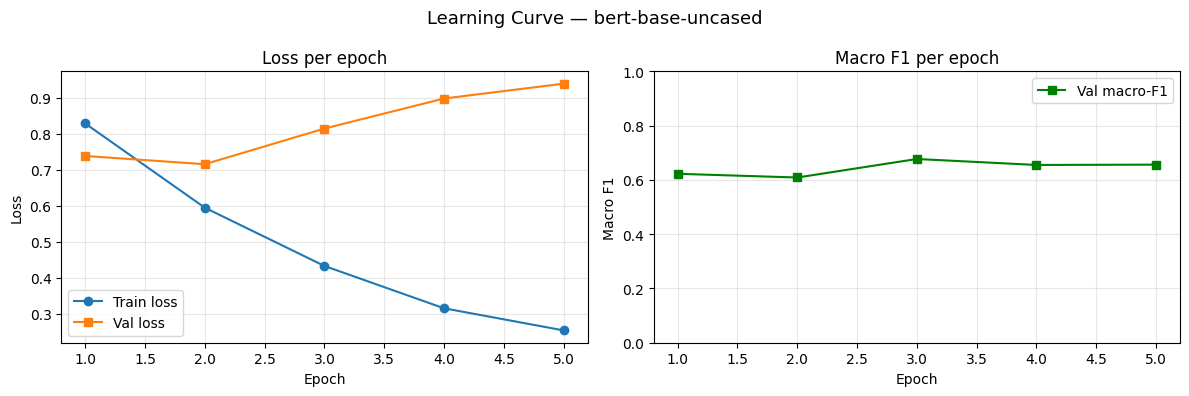

Saved: bert-base-uncased_learning_curve.png



=== bert-base-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.916     0.871     0.893       551
   Interpret      0.937     0.962     0.949      2720
      Reveal      0.959     0.914     0.936      1648
      Revise      0.833     0.911     0.870       350

    accuracy                          0.934      5269
   macro avg      0.911     0.915     0.912      5269
weighted avg      0.935     0.934     0.934      5269


=== bert-base-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat             480              57           10            4
true_Interpret             19            2616           44           41
true_Reveal                22             101         1506           19
true_Revise                 3              17           11          319


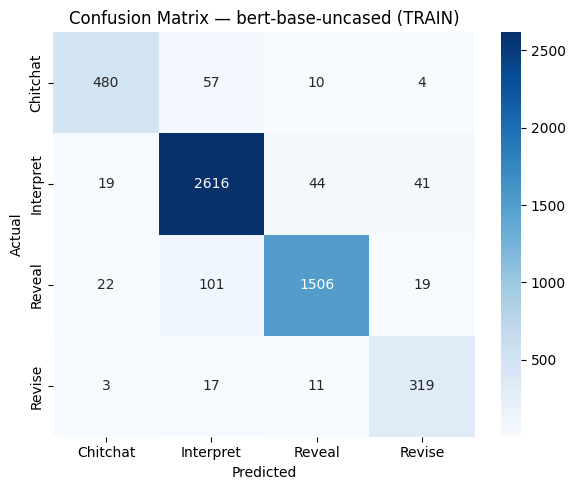


=== bert-base-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.795     0.816     0.805        38
   Interpret      0.858     0.849     0.854       292
      Reveal      0.825     0.733     0.776       161
      Revise      0.188     0.500     0.273        12

    accuracy                          0.801       503
   macro avg      0.666     0.725     0.677       503
weighted avg      0.827     0.801     0.811       503


=== bert-base-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              31               5            1            1
true_Interpret              5             248           22           17
true_Reveal                 3              32          118            8
true_Revise                 0               4            2            6


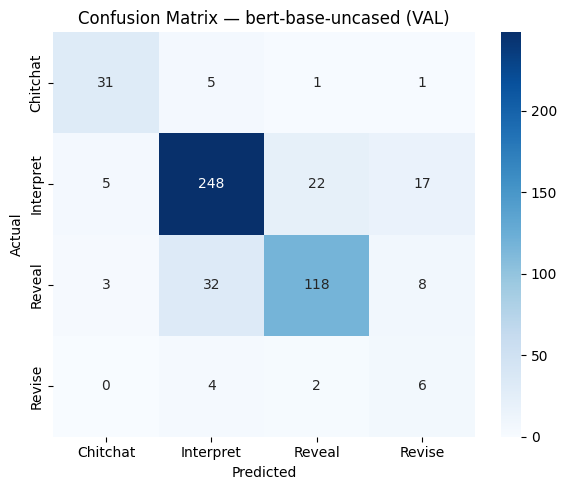


=== bert-base-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,32
1,Interpret,Reveal,22
2,Interpret,Revise,17
3,Reveal,Revise,8
4,Interpret,Chitchat,5
5,Chitchat,Interpret,5
6,Revise,Interpret,4
7,Reveal,Chitchat,3
8,Revise,Reveal,2
9,Chitchat,Revise,1



=== bert-base-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: I wanna a plane.,Interpret,Reveal
5,USER: I want a mountain bike,Revise,Reveal
9,"USER: OK, thanks.",Reveal,Interpret
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
17,USER: I want a Collapsible Water Bottle,Reveal,Revise
22,"USER: Hello, I'm more interested in purchasing...",Interpret,Reveal
24,USER: Do you have smart projectors? At least w...,Reveal,Revise
32,USER: you rubbish.,Interpret,Chitchat
33,USER: I want to phone holder for my iphone 16 ...,Reveal,Revise
34,USER: I want a tripod to take pictures more st...,Interpret,Revise



=== bert-base-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.667     0.667     0.667        54
   Interpret      0.853     0.859     0.856       391
      Reveal      0.812     0.701     0.752       197
      Revise      0.068     0.150     0.094        20

    accuracy                          0.775       662
   macro avg      0.600     0.594     0.592       662
weighted avg      0.802     0.775     0.787       662


=== bert-base-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise
true_Chitchat              36              11            6            1
true_Interpret              8             336           20           27
true_Reveal                 9              37          138           13
true_Revise                 1              10            6            3


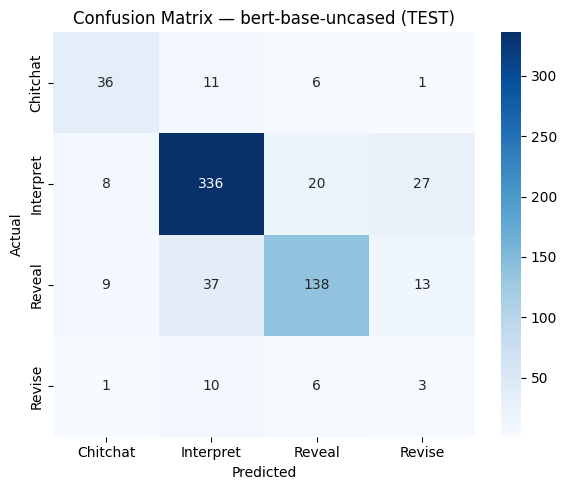


=== bert-base-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,37
1,Interpret,Revise,27
2,Interpret,Reveal,20
3,Reveal,Revise,13
4,Chitchat,Interpret,11
5,Revise,Interpret,10
6,Reveal,Chitchat,9
7,Interpret,Chitchat,8
8,Revise,Reveal,6
9,Chitchat,Reveal,6



=== bert-base-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: I want something bigger.,Reveal,Interpret
2,USER: ok,Reveal,Interpret
10,USER: For women.,Reveal,Interpret
13,USER: Want a white one,Reveal,Revise
14,USER: OK,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: No prefered brand, but I don't want leno...",Revise,Interpret
23,"USER: The second is too expensive, and i do no...",Revise,Interpret
25,"USER: I’m looking for a smartwatch for kids, w...",Reveal,Revise
27,"USER: camera is not necessary, I'd like the st...",Revise,Interpret



=== Compact metrics summary ===


,split,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,samples,chitchat_f1,chitchat_support,interpret_f1,interpret_support,reveal_f1,reveal_support,revise_f1,revise_support
0,TRAIN,bert-base-uncased,0.933953,0.911213,0.914543,0.912122,0.934810,0.933953,0.933956,5269,0.893023,551,0.949374,2720,0.935694,1648,0.870396,350
1,VAL,bert-base-uncased,0.801193,0.666420,0.724506,0.676985,0.826805,0.801193,0.811407,503,0.805195,38,0.853701,292,0.776316,161,0.272727,12
2,TEST,bert-base-uncased,0.774924,0.599851,0.594127,0.592128,0.801696,0.774924,0.786622,662,0.666667,54,0.856051,391,0.752044,197,0.093750,20


Saved metrics summary: /content/drive/MyDrive/intent9Aug/context_ablation_current_only_4class/bert-base-uncased_all_split_metrics.csv


,Context,Model,Seed,Accuracy,Macro_F1,Weighted_F1,Chitchat_F1,Interpret_F1,Reveal_F1,Revise_F1,Test_samples
0,Current utterance only,BERT-base,42,0.774924,0.592128,0.786622,0.666667,0.856051,0.752044,0.09375,662


Saved manuscript-ready context-ablation row.


In [21]:
bert_trainer, bert_test_metrics = run_model(
    "bert-base-uncased",
    num_epochs=NUM_EPOCHS,
)

# Save one manuscript-ready row for the context-ablation table.
context_result = pd.DataFrame([{
    "Context": "Current utterance only",
    "Model": "BERT-base",
    "Seed": RANDOM_STATE,
    "Accuracy": bert_test_metrics["accuracy"],
    "Macro_F1": bert_test_metrics["macro_f1"],
    "Weighted_F1": bert_test_metrics["weighted_f1"],
    "Chitchat_F1": bert_test_metrics.get("chitchat_f1"),
    "Interpret_F1": bert_test_metrics.get("interpret_f1"),
    "Reveal_F1": bert_test_metrics.get("reveal_f1"),
    "Revise_F1": bert_test_metrics.get("revise_f1"),
    "Test_samples": bert_test_metrics["samples"],
}])

display(context_result)
context_result.to_csv(
    os.path.join(RESULTS_DIR, "context_ablation_current_utterance_only_result.csv"),
    index=False,
)
print("Saved manuscript-ready context-ablation row.")


## Context-ablation validity checklist

Before using the result in the manuscript, confirm the printed checks show:

- train/validation/test conversation overlap = 0;
- augmentation source overlap with validation/test = 0;
- augmentation missing source turns = 0;
- augmentation changed labels = 0;
- train/validation/test row counts match the full-context experiment;
- current-only inputs contain exactly one `USER:` marker and no `SYSTEM:` history;
- BERT-base uses the same seed/hyperparameters/class weighting as the full-context run.
